# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:**

Устройство: Google Colab, GPU Tesla T4. Модель: [`cointegrated/rubert-tiny2`](https://huggingface.co/cointegrated/rubert-tiny2), revision `e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae`, лицензия MIT; в 6.2 - [`google-bert/bert-base-multilingual-cased`](https://huggingface.co/google-bert/bert-base-multilingual-cased), revision `3f076fdb1ab68d5b2880cb87a0886f315b8146f8`, Apache 2.0.

Датасет: WikiNEuRal, русская часть ([`Babelscape/wikineural`](https://huggingface.co/datasets/Babelscape/wikineural), файлы `data/{train,val,test}_ru`, revision `74c9b9dca034bb1606a6769457983904bd976803`), лицензия CC BY-NC-SA 4.0. Бонусы: 6.2, 6.3, 6.4, 6.5.

Источники: документация transformers (`Trainer`, `TrainingArguments`), datasets, seqeval, onnxruntime (`quantize_dynamic`).

Бонус 6.1 не выполнялся.

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.14.1+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'cointegrated/rubert-tiny2'
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}


config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:**

`rubert-tiny2` - маленький русский BERT (29.1M параметров, 3 слоя, hidden 312, 112 МБ, батч 32 x 64 за 7.4 мс на T4): обучение на 92 тыс. предложений занимает минуты, лицензия MIT. `DeepPavlov/rubert-base-cased` (~180M) и `bert-base-multilingual-cased` (177M) в ~6 раз больше и медленнее, но обычно точнее; mBERT к тому же режет русские слова мельче (1.74 сабворда на слово против 1.25), а у rubert-base не указана лицензия. Без `revision` владелец может перезалить веса, токенизатор или конфиг - изменятся словарь, разбиение на сабворды и метрики, результат станет невоспроизводимым.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

model.safetensors: reconstructing file:   0%|          |  0.00B /  118MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def n_params(module):
    return sum(p.numel() for p in module.parameters())


def params_by_block(model):
    base = model.base_model
    layers = [n_params(layer) for layer in base.encoder.layer]
    blocks = dict(embeddings=n_params(base.embeddings), encoder=sum(layers), head=n_params(model.classifier))
    return dict(blocks, other=n_params(model) - sum(blocks.values()), layers=layers)

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)
for k, v in enc.items():
    print(f'{k:<15} {tuple(v.shape)}')
print(f'{"hidden_states":<15} {len(out.hidden_states)} x {tuple(out.hidden_states[0].shape)}')
print(f'{"logits":<15} {tuple(out.logits.shape)}')
for i, words in enumerate(demo_texts):
    print(f'{len(words)} слов -> {enc.tokens(i)}')

input_ids       (2, 11)
token_type_ids  (2, 11)
attention_mask  (2, 11)
hidden_states   4 x (2, 11, 312)
logits          (2, 11, 7)
6 слов -> ['[CLS]', 'Петр', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке', '.', '[SEP]']
6 слов -> ['[CLS]', 'IT', '##M', '##O', 'University', 'is', 'in', 'Saint', 'Petersburg', '[SEP]', '[PAD]']


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 7.4 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:**

`input_ids` и `attention_mask` (2, 11) -> эмбеддинги (2, 11, 312) = `hidden_states[0]` -> 3 слоя энкодера, форма не меняется (`hidden_states[1..3]`) -> голова `Linear(312, 7)` -> logits (2, 11, 7). Больше всего параметров в эмбеддингах - 26.8M (92.1%): словарь 83 828 x 312; энкодер 2.3M (7.9%), голова 2 191. Токены обмениваются информацией только в слоях энкодера (attention), эмбеддинги и голова работают с каждым токеном отдельно. `T` = 11 больше 6 слов из-за сабвордов (`Чайковский` -> `Чайк ##овский`), `[CLS]`, `[SEP]` и `[PAD]`.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

README.md:   0%|          | 0.00/158k [00:00<?, ?B/s]

ru/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  809kB            

ru/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  816kB            

ru/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.63MB            

ru/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID, DATASET_CONFIG = 'Babelscape/wikineural', 'ru'
DATASET_REVISION = '74c9b9dca034bb1606a6769457983904bd976803'
wikineural = load_dataset(DATASET_ID, revision=DATASET_REVISION,
                          data_files={s: f'data/{s}_ru-00000-of-00001.parquet' for s in ('train', 'val', 'test')})
raw = DatasetDict(train=wikineural['train'], validation=wikineural['val'], test=wikineural['test'])
LABEL_NAMES = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
raw

README.md:   0%|          | 0.00/5.27k [00:00<?, ?B/s]

data/train_ru-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 9.12MB            

data/train_ru-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/val_ru-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.12MB            

data/val_ru-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test_ru-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.11MB            

data/test_ru-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating val split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 92320
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11540
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11580
    })
})

             предл.     слов    LOC   MISC    ORG    PER  без сущн.
train         92320  1810457  71090  23594  20236  33282       0.0%
validation    11540   216818   8851   2642   2710   4007       0.0%
test          11580   217392   8596   2962   3051   3489       0.0%
LOC   длина спана: средняя 1.12, max 11, длиннее 3 слов 0.5%
MISC  длина спана: средняя 1.54, max 24, длиннее 3 слов 6.4%
ORG   длина спана: средняя 1.62, max 17, длиннее 3 слов 4.8%
PER   длина спана: средняя 1.37, max 10, длиннее 3 слов 0.4%
длина предложения: медиана 17, 95-й перцентиль 41, max 256


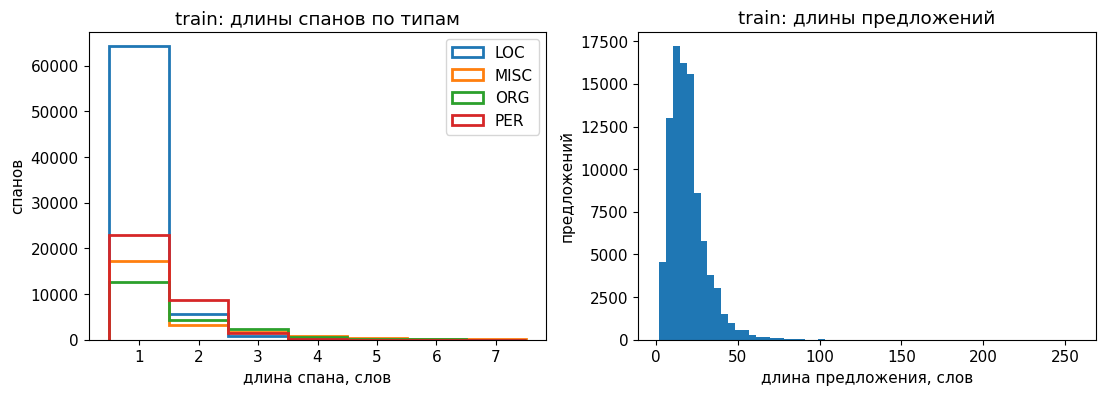

In [14]:
from seqeval.metrics.sequence_labeling import get_entities

types = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
entities = {split: [get_entities([LABEL_NAMES[i] for i in tags]) for tags in ds['ner_tags']] for split, ds in raw.items()}
print(f'{"":<11}{"предл.":>8}{"слов":>9}' + ''.join(f'{t:>7}' for t in types) + f'{"без сущн.":>11}')
for split, ents in entities.items():
    counts = collections.Counter(t for sent in ents for t, _, _ in sent)
    n_words = sum(map(len, raw[split]['tokens']))
    print(f'{split:<11}{len(ents):>8}{n_words:>9}' + ''.join(f'{counts[t]:>7}' for t in types)
          + f'{sum(not s for s in ents) / len(ents):>11.1%}')

span_len = {t: np.array([e - s + 1 for sent in entities['train'] for typ, s, e in sent if typ == t]) for t in types}
sent_len = np.array([len(ws) for ws in raw['train']['tokens']])
for t, lengths in span_len.items():
    print(f'{t:<5} длина спана: средняя {lengths.mean():.2f}, max {lengths.max()}, длиннее 3 слов {np.mean(lengths > 3):.1%}')
print(f'длина предложения: медиана {np.median(sent_len):.0f}, 95-й перцентиль {np.percentile(sent_len, 95):.0f}, max {sent_len.max()}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for t, lengths in span_len.items():
    axes[0].hist(lengths, bins=np.arange(0.5, 8.5), histtype='step', linewidth=2, label=t)
axes[0].set(xlabel='длина спана, слов', ylabel='спанов', title='train: длины спанов по типам')
axes[0].legend()
axes[1].hist(sent_len, bins=60)
axes[1].set(xlabel='длина предложения, слов', ylabel='предложений', title='train: длины предложений')
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:**

WikiNEuRal (Babelscape, EMNLP 2021), русская часть, CC BY-NC-SA 4.0; разметка автоматическая: ссылки Википедии + BabelNet + фильтр нейросетью, без ручной проверки. Типы PER / ORG / LOC / MISC, 92 320 / 11 540 / 11 580 предложений; в train 48% сущностей - LOC (71 090), реже всего ORG (20 236) и MISC (23 594). В каждом предложении есть сущность, чего не бывает в обычном тексте; спаны короткие (1.1-1.6 слова), длинные - в основном у MISC и ORG (длиннее 3 слов 6.4% и 4.8%), на них труднее границы. Предложения короткие (медиана 17 слов), но встречаются до 256; шум разметки виден в 2.2 и 5.1.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    spans = []
    for i, tag in enumerate(tags):
        if tag == 'O':
            continue
        kind = tag[2:]
        if tag[0] == 'I' and spans and spans[-1][1] == i and spans[-1][2] == kind:
            spans[-1] = (spans[-1][0], i + 1, kind)
        else:
            spans.append((i, i + 1, kind))
    return spans


def spans_to_bio(spans, n_words):
    tags = ['O'] * n_words
    for start, end, kind in spans:
        tags[start:end] = [f'B-{kind}'] + [f'I-{kind}'] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    labels, prev = [], None
    for w in word_ids:
        if w is None or (w == prev and b_to_i is None):
            labels.append(-100)
        elif w == prev:
            labels.append(b_to_i.get(word_labels[w], word_labels[w]))
        else:
            labels.append(word_labels[w])
        prev = w
    return labels

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
for split, ds in raw.items():
    gold = [[LABEL_NAMES[i] for i in tags] for tags in ds['ner_tags']]
    path = DATA_DIR / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as f:
        for words, tags in zip(ds['tokens'], gold):
            f.write(json.dumps(dict(tokens=words, spans=bio_to_spans(tags)), ensure_ascii=False) + '\n')
    with path.open(encoding='utf-8') as f:
        records = [json.loads(line) for line in f]
    back = [spans_to_bio([tuple(s) for s in r['spans']], len(r['tokens'])) for r in records]
    assert len(back) == len(gold) and all(bio_to_spans(b) == bio_to_spans(g) for b, g in zip(back, gold))
    differ = [i for i, (b, g) in enumerate(zip(back, gold)) if b != g]
    print(f'{split}: {len(records)} предложений, {sum(len(r["spans"]) for r in records)} спанов, '
          f'спаны совпали во всех, BIO дословно не совпал в {len(differ)} (I-X без B-X)')
    for i in differ[:3]:
        print('    исходный BIO -> после спанов:', [(w, g, b) for w, g, b in zip(ds[i]['tokens'], gold[i], back[i]) if g != b])

train: 92320 предложений, 148202 спанов, спаны совпали во всех, BIO дословно не совпал в 3210 (I-X без B-X)
    исходный BIO -> после спанов: [('Вознесения', 'I-MISC', 'B-MISC')]
    исходный BIO -> после спанов: [('«', 'I-MISC', 'B-MISC')]
    исходный BIO -> после спанов: [('Луиса', 'I-PER', 'B-PER')]
validation: 11540 предложений, 18210 спанов, спаны совпали во всех, BIO дословно не совпал в 393 (I-X без B-X)
    исходный BIO -> после спанов: [('Смерть', 'I-MISC', 'B-MISC')]
    исходный BIO -> после спанов: [('Кошка', 'I-MISC', 'B-MISC')]
    исходный BIO -> после спанов: [('Тихий', 'I-MISC', 'B-MISC')]
test: 11580 предложений, 18098 спанов, спаны совпали во всех, BIO дословно не совпал в 464 (I-X без B-X)
    исходный BIO -> после спанов: [('Шоу', 'I-MISC', 'B-MISC')]
    исходный BIO -> после спанов: [('Baby', 'I-MISC', 'B-MISC')]
    исходный BIO -> после спанов: [('Symbian', 'I-MISC', 'B-MISC')]


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/92320 [00:00<?, ? examples/s]

Map:   0%|          | 0/11540 [00:00<?, ? examples/s]

Map:   0%|          | 0/11580 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 92320
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11540
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11580
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']
train: проверено 92236 предложений, обрезано по MAX_LENGTH 83, слов без сабвордов или за обрезкой 2196
[CLS]            None  -100
Детство             0  O
провёл              1  O
в                   2  O
Над                 3  B-LOC
##ь                 3  -100
##сом               3  -100
##бат               3  -100
##е                 3  -100
,                   4  O
с                   5  O
1860                6  O
г                   7  O
.                   8  O
[SEP]            None  -100


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:**

Метки и метрика по словам, поэтому метка ставится один раз на слово; -100 - это `ignore_index` в `CrossEntropyLoss`, такие позиции не дают ни loss, ни градиента. Обрезано 83 предложения train, слов без сабвордов или за обрезкой 2 196 из 1.81M (0.12%) - они получают `O`, на метрику это почти не влияет. Вложенных спанов нет, проблема одна: спан начинается с `I-X` без `B-X` в 3 210 / 393 / 464 предложениях train / validation / test; `bio_to_spans`, как и `seqeval`, считает его началом спана, поэтому спаны после круга BIO -> JSON -> BIO совпали везде.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for word, tag in zip(words, tags):
            counts[word][tag] += 1
    return {word: c.most_common(1)[0][0] for word, c in counts.items()}


def predict_majority(tagger, words):
    return [tagger.get(word, 'O') for word in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_tags = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
majority = fit_majority_tagger(data['train']['tokens'], train_tags)
set_seed(SEED)
random_pred = predict_word_tags(make_model(), val_tokens)
baseline = dict(majority=entity_scores(val_gold, [predict_majority(majority, ws) for ws in val_tokens]),
                random_head=entity_scores(val_gold, random_pred))

train_entities = {(' '.join(ws[s:e]), t) for ws, tags in zip(data['train']['tokens'], train_tags) for s, e, t in bio_to_spans(tags)}
val_entities = [(' '.join(ws[s:e]), t) for ws, tags in zip(val_tokens, val_gold) for s, e, t in bio_to_spans(tags)]
print(f'сущности validation, которые есть в train с тем же текстом и типом: {np.mean([e in train_entities for e in val_entities]):.1%}')
print('случайная голова, теги на validation:', collections.Counter(t for tags in random_pred for t in tags).most_common())
baseline

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

сущности validation, которые есть в train с тем же текстом и типом: 60.1%
случайная голова, теги на validation: [('I-PER', 53044), ('O', 46258), ('B-PER', 38401), ('B-LOC', 19758), ('I-MISC', 16478), ('I-ORG', 13943), ('I-LOC', 12004), ('B-ORG', 11557), ('B-MISC', 5375)]


{'majority': {'f1_micro': np.float64(0.5843722774656773),
  'f1_macro': np.float64(0.5089478842707436),
  'precision': np.float64(0.6450885454666048),
  'recall': np.float64(0.5341021416803954)},
 'random_head': {'f1_micro': np.float64(0.029393424222334538),
  'f1_macro': np.float64(0.028270139891322568),
  'precision': np.float64(0.016691889635223688),
  'recall': np.float64(0.12295442064799561)}}

**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:**

Словарный бейзлайн дает F1 0.584: сущности Википедии часто повторяются - 60.1% сущностей validation есть в train с тем же текстом и типом, почти половина из них - частые LOC. Он ошибается на незнакомых и неоднозначных словах и на многословных спанах, где без контекста ломаются границы. Энкодер со случайной головой дает F1 0.029: признаки энкодера хорошие, но случайная `Linear(312, 9)` с тегами не связана, поэтому теги почти случайны (`O` лишь у 21% слов) - связь появляется только при дообучении.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 2e-4          # подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    if freeze_encoder:
        model.base_model.requires_grad_(False)
    total_steps = math.ceil(len(train_ds) / batch_size) * epochs
    args = TrainingArguments(output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr, weight_decay=0.01,
                             warmup_steps=0.1, per_device_train_batch_size=batch_size,
                             per_device_eval_batch_size=2 * batch_size, eval_strategy='steps',
                             eval_steps=max(1, total_steps // 10), logging_steps=max(1, total_steps // 20),
                             save_strategy='no', fp16=device.type == 'cuda', seed=SEED, report_to='none', disable_tqdm=True)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    start = time.perf_counter()
    trainer.train()
    return trainer.state.log_history, time.perf_counter() - start

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '0.4771', 'grad_norm': '0.9886', 'learning_rate': '9.954e-05', 'epoch': '0.1497'}
{'loss': '0.1019', 'grad_norm': '1.437', 'learning_rate': '0.0001993', 'epoch': '0.2995'}
{'eval_loss': '0.0843', 'eval_runtime': '2.777', 'eval_samples_per_second': '4156', 'eval_steps_per_second': '65.18', 'epoch': '0.2998'}
{'loss': '0.08408', 'grad_norm': '0.65', 'learning_rate': '0.000189', 'epoch': '0.4492'}
{'loss': '0.07659', 'grad_norm': '1.041', 'learning_rate': '0.0001779', 'epoch': '0.599'}
{'eval_loss': '0.0701', 'eval_runtime': '2.699', 'eval_samples_per_second': '4276', 'eval_steps_per_second': '67.07', 'epoch': '0.5997'}
{'loss': '0.07229', 'grad_norm': '0.5795', 'learning_rate': '0.0001668', 'epoch': '0.7487'}
{'loss': '0.06857', 'grad_norm': '1.031', 'learning_rate': '0.0001557', 'epoch': '0.8984'}
{'eval_loss': '0.06383', 'eval_runtime': '2.77', 'eval_samples_per_second': '4166', 'eval_steps_per_second': '65.35', 'epoch': '0.8995'}
{'loss': '0.05807', 'grad_norm': '0.6762', 'le

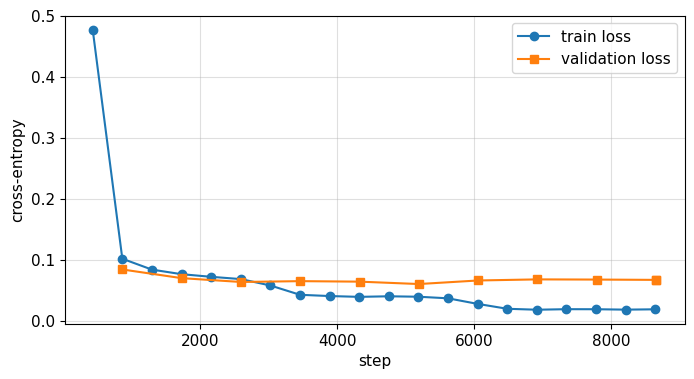

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:**

lr 2e-4 - маленькой модели нужен больше, чем 2e-5 - 5e-5 у base; warmup 10% гасит большие градиенты случайной головы, weight decay 0.01, batch 32, 3 эпохи (8 658 шагов), fp16. Train loss падает все обучение (0.084 -> 0.019), validation loss - до минимума 0.060 около эпохи 1.8, а к концу растет до 0.067: в третьей эпохе начинается легкое переобучение, хотя F1 остается 0.859. Эпох хватило, по кривой хватило бы и двух. Обучение - 269 с на Tesla T4.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    tp = sum(g == p != 'O' for gs, ps in zip(gold, pred) for g, p in zip(gs, ps))
    n_gold = sum(g != 'O' for gs in gold for g in gs)
    n_pred = sum(p != 'O' for ps in pred for p in ps)
    return 2 * tp / (n_gold + n_pred) if n_gold + n_pred else 0.0

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
val_pred = predict_word_tags(model, val_tokens)
test_pred = predict_word_tags(model, test_tokens)
for split, gold_tags, pred_tags in [('validation', val_gold, val_pred), ('test', test_gold, test_pred)]:
    scores = entity_scores(gold_tags, pred_tags)
    print(f'{split}: F1 micro {scores["f1_micro"]:.4f}, macro {scores["f1_macro"]:.4f}, token F1 {token_f1(gold_tags, pred_tags):.4f}')
    print(classification_report(gold_tags, pred_tags, digits=4, zero_division=0))
report = classification_report(test_gold, test_pred, output_dict=True, zero_division=0)
final = dict(entity_scores(test_gold, test_pred), token_f1=token_f1(test_gold, test_pred),
             per_type={t: report[t] for t in ENTITY_TYPES},
             validation=dict(entity_scores(val_gold, val_pred), token_f1=token_f1(val_gold, val_pred)))

validation: F1 micro 0.8593, macro 0.8234, token F1 0.8697
              precision    recall  f1-score   support

         LOC     0.9144    0.9237    0.9191      8851
        MISC     0.7319    0.7358    0.7339      2642
         ORG     0.7502    0.7856    0.7675      2710
         PER     0.8641    0.8822    0.8731      4007

   micro avg     0.8520    0.8668    0.8593     18210
   macro avg     0.8152    0.8318    0.8234     18210
weighted avg     0.8524    0.8668    0.8595     18210

test: F1 micro 0.8577, macro 0.8280, token F1 0.8730
              precision    recall  f1-score   support

         LOC     0.9168    0.9255    0.9212      8596
        MISC     0.7418    0.7546    0.7481      2962
         ORG     0.7402    0.7873    0.7630      3051
         PER     0.8651    0.8948    0.8797      3489

   micro avg     0.8474    0.8683    0.8577     18098
   macro avg     0.8160    0.8405    0.8280     18098
weighted avg     0.8484    0.8683    0.8582     18098



**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:**

Хуже всего MISC (F1 0.748 на test) и ORG (0.763), лучше LOC (0.921) и PER (0.880): MISC разнородный и с длинными спанами, ORG путается с LOC (страна как сборная), оба почти в 3 раза реже LOC. Micro-F1 0.858 выше macro 0.828, потому что micro доминирует легкий LOC (48% спанов). Токенный F1 0.873 выше F1 по сущностям 0.858: при ошибке границы часть слов совпадает и засчитывается, а по сущностям нужно точное совпадение. Пользователю нужна сущность целиком, поэтому ближе F1 по сущностям.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def spans_overlap(a, b):
    return a[0] < b[1] and b[0] < a[1]


def categorize_errors(gold_spans, pred_spans):
    result = []
    for g in gold_spans:
        hits = [p for p in pred_spans if spans_overlap(g, p)]
        same_type = [p for p in hits if p[2] == g[2]]
        if g in pred_spans:
            result.append(('correct', g, g))
        elif same_type:
            result.append(('boundary', g, same_type[0]))
        elif hits:
            result.append(('type', g, hits[0]))
        else:
            result.append(('missed', g, None))
    return result + [('spurious', None, p) for p in pred_spans if not any(spans_overlap(g, p) for g in gold_spans)]

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

categorized = [(i, c, g, p) for i, (gold_tags, pred_tags) in enumerate(zip(val_gold, val_pred))
               for c, g, p in categorize_errors(bio_to_spans(gold_tags), bio_to_spans(pred_tags))]
counts = collections.Counter(c for _, c, _, _ in categorized)
errors = {c: counts[c] for c in ERROR_CATEGORIES}
n_errors = sum(errors.values()) - errors['correct']
print(f'validation: correct {errors["correct"]}, ошибок {n_errors}')
for c in ERROR_CATEGORIES[1:]:
    by_type = collections.Counter((g or p)[2] for _, cat, g, p in categorized if cat == c)
    print(f'{c:<9}{errors[c]:>6} {errors[c] / n_errors:6.1%}   по типам: {dict(by_type.most_common())}')
print('type, истинный -> предсказанный:', dict(collections.Counter(f'{g[2]}->{p[2]}' for _, c, g, p in categorized if c == 'type').most_common()))


def span_text(words, span):
    return '-' if span is None else f'[{" ".join(words[span[0]:span[1]])}] {span[2]}'


rng = random.Random(SEED)
for c in ERROR_CATEGORIES[1:]:
    examples = [e for e in categorized if e[1] == c]
    for i, _, g, p in rng.sample(examples, min(2, len(examples))):
        print(f'\n{c}: gold {span_text(val_tokens[i], g)}  |  pred {span_text(val_tokens[i], p)}\n    {" ".join(val_tokens[i])}')

validation: correct 15784, ошибок 3009
boundary    652  21.7%   по типам: {'ORG': 249, 'MISC': 180, 'LOC': 138, 'PER': 85}
type       1378  45.8%   по типам: {'LOC': 457, 'PER': 333, 'MISC': 325, 'ORG': 263}
missed      396  13.2%   по типам: {'MISC': 193, 'LOC': 80, 'ORG': 69, 'PER': 54}
spurious    583  19.4%   по типам: {'MISC': 266, 'LOC': 138, 'ORG': 100, 'PER': 79}
type, истинный -> предсказанный: {'LOC->PER': 264, 'PER->LOC': 246, 'MISC->ORG': 146, 'ORG->MISC': 120, 'LOC->ORG': 117, 'MISC->LOC': 110, 'ORG->LOC': 98, 'LOC->MISC': 76, 'MISC->PER': 69, 'PER->MISC': 53, 'ORG->PER': 45, 'PER->ORG': 34}

boundary: gold [Внешнеполитическое управление НСДАП] ORG  |  pred [Внешнеполитическое управление] ORG
    1 апреля 1933 года возглавил Внешнеполитическое управление НСДАП ( ) ( АПА ) , при котором было создано т .

boundary: gold [Бундеслиги « Вальдхоф »] ORG  |  pred [« Вальдхоф »] ORG
    После завершения карьеры футболиста Штилике в 1989 году возглавил сборную Швейцарии , затем раб

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:**

Из 3 009 ошибок на validation чаще всего ошибка типа - 1 378 (45.8%), затем границы 652 (21.7%), лишние спаны 583 (19.4%) и пропуски 396 (13.2%). Типы путаются в основном LOC <-> PER (264 и 246: места и объекты, названные именами) и MISC <-> ORG; границы рвутся на длинных названиях (`Внешнеполитическое управление` вместо `... НСДАП`). Часть ошибок - ошибки автоматической разметки: бог `Вакх` размечен как LOC, фамилия `Перкинса` - как MISC (модель в обоих случаях права: PER), название `Opirus` не размечено. Уменьшить ошибки типа можно моделью побольше (mBERT в 6.2 дает +6 пунктов) и чистой разметкой.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '1.426', 'grad_norm': '1.057', 'learning_rate': '9.954e-05', 'epoch': '0.1497'}
{'loss': '0.3699', 'grad_norm': '0.393', 'learning_rate': '0.0001993', 'epoch': '0.2995'}
{'eval_loss': '0.2727', 'eval_runtime': '3.471', 'eval_samples_per_second': '3325', 'eval_steps_per_second': '52.15', 'epoch': '0.2998'}
{'loss': '0.2523', 'grad_norm': '0.2266', 'learning_rate': '0.000189', 'epoch': '0.4492'}
{'loss': '0.2158', 'grad_norm': '0.1824', 'learning_rate': '0.0001779', 'epoch': '0.599'}
{'eval_loss': '0.1914', 'eval_runtime': '3.286', 'eval_samples_per_second': '3512', 'eval_steps_per_second': '55.09', 'epoch': '0.5997'}
{'loss': '0.1996', 'grad_norm': '0.2027', 'learning_rate': '0.0001668', 'epoch': '0.7487'}
{'loss': '0.1936', 'grad_norm': '0.2144', 'learning_rate': '0.0001557', 'epoch': '0.8984'}
{'eval_loss': '0.1704', 'eval_runtime': '2.765', 'eval_samples_per_second': '4174', 'eval_steps_per_second': '65.46', 'epoch': '0.8995'}
{'loss': '0.1825', 'grad_norm': '0.2134', 'learn

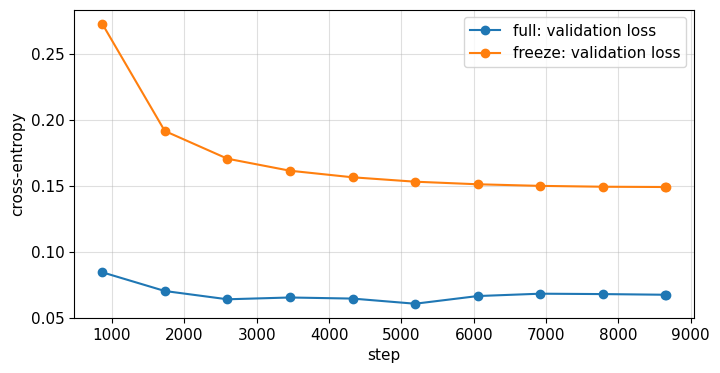

{'setting': 'freeze',
 'full': {'f1_micro': np.float64(0.8593205574912891),
  'f1_macro': np.float64(0.8233663590303156),
  'precision': np.float64(0.8519917953146928),
  'recall': np.float64(0.8667764964305327),
  'train_sec': 268.675644569,
  'trainable_params': 29098929},
 'freeze': {'f1_micro': np.float64(0.6330969517358171),
  'f1_macro': np.float64(0.538917047072917),
  'precision': np.float64(0.6109181901746502),
  'recall': np.float64(0.656946732564525),
  'train_sec': 181.838972217,
  'trainable_params': 2817}}

In [28]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'


def n_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


set_seed(SEED)
frozen = make_model()
frozen_history, RUN_TIMES['train_freeze_sec'] = train_ner(frozen, tokenized['train'], tokenized['validation'],
                                                          freeze_encoder=True, out_dir='runs/freeze')
ablation = dict(setting=ABLATION,
                full=dict(entity_scores(val_gold, val_pred), train_sec=RUN_TIMES['train_main_sec'], trainable_params=n_trainable(model)),
                freeze=dict(entity_scores(val_gold, predict_word_tags(frozen, val_tokens)), train_sec=RUN_TIMES['train_freeze_sec'],
                            trainable_params=n_trainable(frozen)))

plt.figure(figsize=(8, 4))
for name, hist in [('full', history), ('freeze', frozen_history)]:
    plt.plot(*zip(*[(h['step'], h['eval_loss']) for h in hist if 'eval_loss' in h]), 'o-', label=f'{name}: validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()
ablation

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:**

С замороженным энкодером F1 падает с 0.859 до 0.633 при 2 817 обучаемых параметрах вместо 29.1M, а обучение быстрее всего в 1.5 раза (182 с против 269 с). Признаки предобученного `rubert-tiny2` линейно плохо разделяют BIO-теги, а дообучение подстраивает сами представления. Для надежности я бы подобрал отдельный lr для одной головы, попробовал разморозить верхний слой и повторил опыт с несколькими seed.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:**

Дообученный `rubert-tiny2` дает F1 0.858 на test против 0.584 у словарного бейзлайна, за 269 с на T4. Лучше всего распознаются LOC (0.921) и PER (0.880), хуже MISC (0.748) и ORG (0.763); главная ошибка - путаница типов (46%), заметная ее часть - шум автоматической разметки. Замораживать энкодер нельзя (F1 0.633), mBERT дает 0.920 ценой 6x времени (6.2), а смена регистра почти обнуляет качество (0.189 и 0.042, 6.3). Ограничения: один seed, silver-разметка и в train, и в test, только Википедия. Дальше - аугментация регистра, дистилляция mBERT и проверка на вручную размеченных данных.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "Babelscape/wikineural/ru", "classes": ["LOC", "MISC", "ORG", "PER"], "n_train": 92320, "n_val": 11540, "n_test": 11580, "params_total": 29098929, "ablation": {"setting": "freeze", "full": {"f1_micro": 0.8593205574912891, "f1_macro": 0.8233663590303156, "precision": 0.8519917953146928, "recall": 0.8667764964305327, "train_sec": 268.675644569, "trainable_params": 29098929}, "freeze": {"f1_micro": 0.6330969517358171, "f1_macro": 0.538917047072917, "precision": 0.6109181901746
final F1 micro 0.8577


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:**

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
if '6.2' in BONUS_TASKS:
    MODEL2_ID, REVISION2, LR2 = 'google-bert/bert-base-multilingual-cased', '3f076fdb1ab68d5b2880cb87a0886f315b8146f8', 3e-5
    tokenizer2 = AutoTokenizer.from_pretrained(MODEL2_ID, revision=REVISION2)
    tokenized2 = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(tok=tokenizer2))
    set_seed(SEED)
    model2 = make_model(MODEL2_ID, REVISION2)
    history2, RUN_TIMES['train_model2_sec'] = train_ner(model2, tokenized2['train'], tokenized2['validation'], lr=LR2,
                                                        tok=tokenizer2, out_dir='runs/model2')
    n_val_words = sum(map(len, val_tokens))
    model_comparison = {}
    for name, m, tok, tok_ds, train_sec in [(MODEL_ID, model, tokenizer, tokenized, RUN_TIMES['train_main_sec']),
                                            (MODEL2_ID, model2, tokenizer2, tokenized2, RUN_TIMES['train_model2_sec'])]:
        predict_word_tags(m, val_tokens[:256], tok=tok)
        start = time.perf_counter()
        pred = predict_word_tags(m, val_tokens, tok=tok)
        infer_sec = time.perf_counter() - start
        model_comparison[name] = dict(entity_scores(val_gold, pred),
                                      test_f1=f1_score(test_gold, predict_word_tags(m, test_tokens, tok=tok)),
                                      params=n_params(m), weights_mb=n_params(m) * 4 / 2**20, train_sec=train_sec,
                                      infer_val_sec=infer_sec, lr=LR if m is model else LR2,
                                      subwords_per_word=(sum(map(len, tok_ds['validation']['input_ids'])) - 2 * len(val_tokens)) / n_val_words)
    for name, r in model_comparison.items():
        print(f'{name:<42} val F1 {r["f1_micro"]:.4f}  test F1 {r["test_f1"]:.4f}  params {r["params"] / 1e6:.0f}M ({r["weights_mb"]:.0f} MB)  '
              f'train {r["train_sec"]:.0f} s  inference val {r["infer_val_sec"]:.1f} s  сабвордов на слово {r["subwords_per_word"]:.2f}')

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

Map:   0%|          | 0/92320 [00:00<?, ? examples/s]

Map:   0%|          | 0/11540 [00:00<?, ? examples/s]

Map:   0%|          | 0/11580 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '0.3731', 'grad_norm': '1.726', 'learning_rate': '1.493e-05', 'epoch': '0.1497'}
{'loss': '0.06585', 'grad_norm': '2.536', 'learning_rate': '2.99e-05', 'epoch': '0.2995'}
{'eval_loss': '0.05537', 'eval_runtime': '17.82', 'eval_samples_per_second': '647.7', 'eval_steps_per_second': '10.16', 'epoch': '0.2998'}
{'loss': '0.05412', 'grad_norm': '0.914', 'learning_rate': '2.835e-05', 'epoch': '0.4492'}
{'loss': '0.05078', 'grad_norm': '0.9532', 'learning_rate': '2.668e-05', 'epoch': '0.599'}
{'eval_loss': '0.0458', 'eval_runtime': '17.67', 'eval_samples_per_second': '652.9', 'eval_steps_per_second': '10.24', 'epoch': '0.5997'}
{'loss': '0.04691', 'grad_norm': '0.9094', 'learning_rate': '2.502e-05', 'epoch': '0.7487'}
{'loss': '0.04436', 'grad_norm': '1.783', 'learning_rate': '2.336e-05', 'epoch': '0.8984'}
{'eval_loss': '0.03967', 'eval_runtime': '17.71', 'eval_samples_per_second': '651.7', 'eval_steps_per_second': '10.22', 'epoch': '0.8995'}
{'loss': '0.04018', 'grad_norm': '1.035

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:**

mBERT лучше: F1 0.920 на test против 0.858 (+6.2 пункта). Цена: 177M параметров против 29M (676 МБ против 111 МБ), обучение в 6.2 раза дольше (1 677 с против 269 с), предсказание в 3 раза медленнее (19.4 с против 6.4 с на validation). Сравнение честное: те же данные, эпохи, batch, расписание, seed и оценка по словам; отличается только lr (3e-5 против 2e-4), стандартный для размера модели.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [32]:
if '6.3' in BONUS_TASKS:
    TRANSLIT = dict(zip('абвгдеёжзийклмнопрстуфхцчшщъыьэюя',
                        ['a', 'b', 'v', 'g', 'd', 'e', 'e', 'zh', 'z', 'i', 'y', 'k', 'l', 'm', 'n', 'o', 'p', 'r', 's', 't', 'u',
                         'f', 'kh', 'ts', 'ch', 'sh', 'shch', '', 'y', '', 'e', 'yu', 'ya']))


    def translit(word):
        return ''.join(TRANSLIT.get(ch.lower(), ch).capitalize() if ch.isupper() else TRANSLIT.get(ch, ch) for ch in word)


    def typo(word, rng):
        if len(word) < 4 or rng.random() > 0.3:
            return word
        i = rng.randrange(1, len(word) - 2)
        return word[:i] + word[i + 1] + word[i] + word[i + 2:]


    rng = random.Random(SEED)
    corruptions = dict(clean=lambda w: w, lower=str.lower, upper=str.upper, typos=lambda w: typo(w, rng), translit=translit)
    shift = {}
    for name, corrupt in corruptions.items():
        corrupted = [[corrupt(w) for w in ws] for ws in val_tokens]
        pred = predict_word_tags(model, corrupted)
        report = classification_report(val_gold, pred, output_dict=True, zero_division=0)
        shift[name] = dict(f1_micro=f1_score(val_gold, pred), **{t: report[t]['f1-score'] for t in ENTITY_TYPES})
        print(f'{name:<9} F1 {shift[name]["f1_micro"]:.4f}  ' + '  '.join(f'{t} {shift[name][t]:.3f}' for t in ENTITY_TYPES)
              + f'   пример: {" ".join(corrupted[0][:12])}')

clean     F1 0.8593  LOC 0.919  MISC 0.734  ORG 0.767  PER 0.873   пример: Тем не менее , он должен был остаться на своем посту Председателя
lower     F1 0.1890  LOC 0.112  MISC 0.272  ORG 0.260  PER 0.111   пример: тем не менее , он должен был остаться на своем посту председателя
upper     F1 0.0418  LOC 0.035  MISC 0.067  ORG 0.051  PER 0.000   пример: ТЕМ НЕ МЕНЕЕ , ОН ДОЛЖЕН БЫЛ ОСТАТЬСЯ НА СВОЕМ ПОСТУ ПРЕДСЕДАТЕЛЯ
typos     F1 0.8044  LOC 0.873  MISC 0.671  ORG 0.695  PER 0.811   пример: Тем не менее , он должен был остаться на свеом посту Председателя
translit  F1 0.2113  LOC 0.172  MISC 0.209  ORG 0.197  PER 0.276   пример: Tem ne menee , on dolzhen byl ostatsya na svoem postu Predsedatelya


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:**

Сильнее всего бьет регистр: в верхнем F1 падает с 0.859 до 0.042, в нижнем - до 0.189; транслит - 0.211, опечатки - 0.804. Модель cased, и заглавная буква - главный признак сущности: в нижнем регистре сущность не отличить от обычного слова, а ВЕРХНИЙ РЕГИСТР токенизатор режет на редкие куски, незнакомые модели. Опечатка портит один-два сабворда, контекст и заглавная буква остаются. Помогла бы аугментация регистра при обучении.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    import subprocess
    import sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'onnx', 'onnxruntime', 'onnxscript'], check=True)
    import onnxruntime as ort
    from onnxruntime.quantization import QuantType, quantize_dynamic
    from transformers.modeling_outputs import TokenClassifierOutput


    class OnnxTagger:
        def __init__(self, path, config):
            self.session = ort.InferenceSession(str(path), providers=['CPUExecutionProvider'])
            self.config = config

        def eval(self):
            return self

        def to(self, dev):
            return self

        def __call__(self, **enc):
            return TokenClassifierOutput(logits=torch.from_numpy(self.session.run(['logits'], {k: v.numpy() for k, v in enc.items()})[0]))


    def latency_ms(m, batch, dev):
        x = {k: v.to(dev) for k, v in batch.items()}
        with torch.inference_mode():
            m(**x).logits.cpu()
            start = time.perf_counter()
            for _ in range(20):
                m(**x).logits.cpu()
        return (time.perf_counter() - start) / 20 * 1000


    cpu = torch.device('cpu')
    cpu_model = copy.deepcopy(model).to(cpu).eval()
    batch = tokenizer(val_tokens[:32], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
    input_names = ['input_ids', 'attention_mask', 'token_type_ids']
    onnx_path, int8_path = Path('runs/ner.onnx'), Path('runs/ner_int8.onnx')
    torch.onnx.export(cpu_model, tuple(batch[k] for k in input_names), onnx_path, input_names=input_names, output_names=['logits'],
                      dynamic_axes={k: {0: 'batch', 1: 'seq'} for k in [*input_names, 'logits']}, dynamo=False)
    quantize_dynamic(onnx_path, int8_path, weight_type=QuantType.QInt8)

    torch_mb = n_params(model) * 4 / 2**20
    variants = {f'torch fp32, {DEVICE_NAME}': (model, device, torch_mb), 'torch fp32, CPU': (cpu_model, cpu, torch_mb),
                'ONNX Runtime fp32, CPU': (OnnxTagger(onnx_path, model.config), cpu, onnx_path.stat().st_size / 2**20),
                'ONNX Runtime int8, CPU': (OnnxTagger(int8_path, model.config), cpu, int8_path.stat().st_size / 2**20)}
    speed = {}
    for name, (m, dev, size_mb) in variants.items():
        speed[name] = dict(latency_ms=latency_ms(m, batch, dev), f1_val=f1_score(val_gold, predict_word_tags(m, val_tokens, dev=dev)),
                           size_mb=size_mb)
        print(f'{name:<32} batch {tuple(batch["input_ids"].shape)}: {speed[name]["latency_ms"]:7.1f} ms   '
              f'F1 val {speed[name]["f1_val"]:.4f}   {speed[name]["size_mb"]:.0f} MB')
    print(f'CPU: {os.cpu_count()} потоков, torch threads {torch.get_num_threads()}')

/tmp/ipykernel_623/1285384152.py:40: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(cpu_model, tuple(batch[k] for k in input_names), onnx_path, input_names=input_names, output_names=['logits'],
/usr/local/lib/python3.13/dist-packages/transformers/masking_utils.py:208: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if (padding_length := kv_length + kv_offset - attention_mask.shape[-1]) > 0:
/usr/local/lib/python3.13/dist-pac

torch fp32, Tesla T4             batch (32, 65):     7.0 ms   F1 val 0.8593   111 MB
torch fp32, CPU                  batch (32, 65):   119.9 ms   F1 val 0.8593   111 MB
ONNX Runtime fp32, CPU           batch (32, 65):   179.2 ms   F1 val 0.8593   111 MB
ONNX Runtime int8, CPU           batch (32, 65):   151.7 ms   F1 val 0.8581   28 MB
CPU: 2 потоков, torch threads 1


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:**

На CPU Colab (2 потока, батч 32 x 65): torch - 119.9 мс, ONNX Runtime fp32 - 179.2 мс, int8 - 151.7 мс, то есть ускорения нет; на T4 - 7.0 мс. F1 у ONNX не изменился (0.8593), у int8 упал на 0.0012, файл int8 в 4 раза меньше (28 МБ). У `rubert-tiny2` 92% параметров - эмбеддинги (поиск в таблице, вычислений почти нет), а слои маленькие (312 x 600), поэтому время уходит на накладные расходы, а не на умножения; ONNX и квантизация выигрывают на больших моделях.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

seqeval F1 на тех же предсказаниях: 0.8593
{
 "mean": {
  "best_threshold": 0.7,
  "best_f1": 0.863872571170357,
  "f1_at_0": 0.8593205574912892,
  "precision_at_best": 0.8892894522618909,
  "recall_at_best": 0.8398682042833608,
  "precision_at_0": 0.8519917953146928,
  "recall_at_0": 0.8667764964305327
 },
 "min": {
  "best_threshold": 0.63,
  "best_f1": 0.8631004305371865,
  "f1_at_0": 0.8593205574912892,
  "precision_at_best": 0.8850926299994228,
  "recall_at_best": 0.8421746293245469,
  "precision_at_0": 0.8519917953146928,
  "recall_at_0": 0.8667764964305327
 }
}


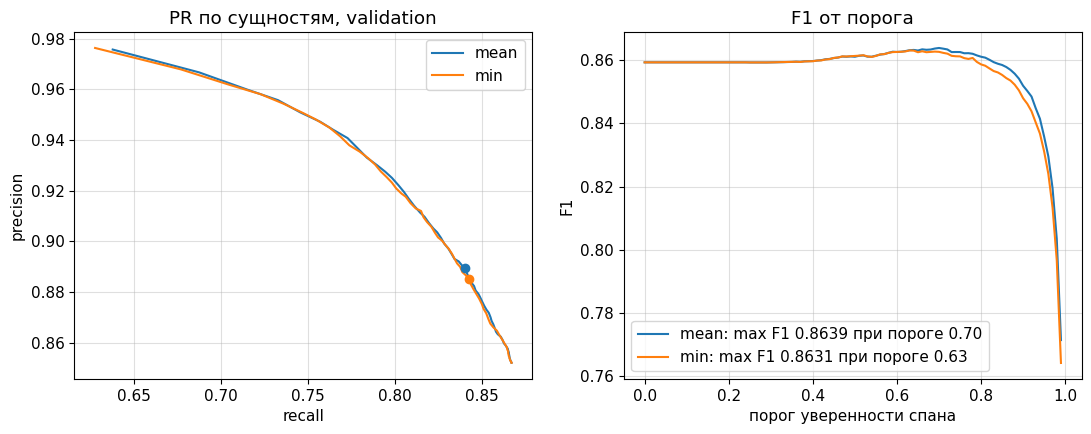

In [34]:
if '6.5' in BONUS_TASKS:
    val_tags, val_probs = predict_word_tags(model, val_tokens, return_probs=True)
    hits, span_conf = [], dict(mean=[], min=[])
    for tags, probs, gold_tags in zip(val_tags, val_probs, val_gold):
        gold_spans = set(bio_to_spans(gold_tags))
        for s, e, t in bio_to_spans(tags):
            hits.append((s, e, t) in gold_spans)
            span_conf['mean'].append(np.mean(probs[s:e]))
            span_conf['min'].append(np.min(probs[s:e]))
    hits = np.array(hits)
    n_gold = sum(len(bio_to_spans(t)) for t in val_gold)
    thresholds = np.round(np.arange(0, 1, 0.01), 2)
    threshold_results = {}
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for agg, conf_values in span_conf.items():
        conf_values = np.array(conf_values)
        n_pred = np.array([(conf_values >= t).sum() for t in thresholds])
        tp = np.array([hits[conf_values >= t].sum() for t in thresholds])
        precision, recall, f1 = tp / np.maximum(n_pred, 1), tp / n_gold, 2 * tp / (n_pred + n_gold)
        best = int(f1.argmax())
        threshold_results[agg] = dict(best_threshold=thresholds[best], best_f1=f1[best], f1_at_0=f1[0],
                                      precision_at_best=precision[best], recall_at_best=recall[best],
                                      precision_at_0=precision[0], recall_at_0=recall[0])
        axes[0].plot(recall, precision, label=agg)
        axes[0].scatter(recall[best], precision[best], zorder=3)
        axes[1].plot(thresholds, f1, label=f'{agg}: max F1 {f1[best]:.4f} при пороге {thresholds[best]:.2f}')
    print(f'seqeval F1 на тех же предсказаниях: {f1_score(val_gold, val_tags):.4f}')
    print(json.dumps(json_ready(threshold_results), indent=1))
    axes[0].set(xlabel='recall', ylabel='precision', title='PR по сущностям, validation')
    axes[1].set(xlabel='порог уверенности спана', ylabel='F1', title='F1 от порога')
    for ax in axes:
        ax.legend()
        ax.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:**

Лучший F1 0.8639 при пороге 0.70 по средней уверенности (0.8631 при 0.63 по минимальной) против 0.8593 без порога - всего +0.005. У однословных спанов средняя и минимальная совпадают, у многословных минимальная строже, поэтому ее порог ниже. Порог только выкидывает найденные спаны и не добавляет новые, поэтому recall может лишь падать.